# MSH chain on a 2D substrate: LDOS, dense and sparse reference

**Goal.** The local density of states (LDOS) of the MSH chain on the substrate at both parameter points, as the reference for
`msh_substrate_ldos_tn.ipynb`, and the cost of computing it with dense and sparse methods as the substrate grows.

**What is computed.** Below the substrate gap (3.3 at the benchmark point, 0.60 at the leaking point) the only states are those
bound to the chain: 24 at the benchmark point and 106 at the leaking point at every size checked. So the subgap LDOS is exactly
$A(\mathbf r, \omega) = \sum_k w_k(\mathbf r)\,\delta_\eta(\omega - E_k)$ with the weights $w_k$ of those states, broadened with a Lorentzian of
half-width $\eta$. Inside the gap $|\omega| < E_{\rm gap}$ only the zero-mode pair contributes (the zero-bias LDOS).

**Sizes and coordinates.** Sizes count lattice sites, $N = N_x N_y$; each site has 4 components (Nambu × spin), so vectors have
$D = 4N$ entries. Cuts are along the chain row ($i_x - x_0$, chain at $0 \dots \ell-1$) and across the chain at its first site and at its
middle ($i_y - i_{y0}$, chain row at 0). Weights are summed over spin; "particle + hole" sums all four components, "particle only"
the electron part an STM tip measures.

**Code.** Model from `substrate_model.py`. Results: `ldos_py_zerobias.csv`, `ldos_py_dense.csv`, `ldos_py_subgap.csv`,
`ldos_kpm_site.csv` (committed) and `data/ldos/` (cuts and spectra, not committed). Section 2 needs the zero modes
`data/td_py_psi_*.npz` of `msh_substrate_td_python.ipynb`; section 6 reads the TN results of `msh_substrate_ldos_tn.ipynb`.
All run flags are off: the notebook loads the saved results in a few seconds; set a flag to `True` to recompute that section.

**Contents**
1. Setup
2. Zero-bias LDOS from the sparse zero mode
3. Energy-resolved LDOS at small sizes (dense)
4. Subgap LDOS on large substrates (MUMPS shift-invert)
5. Per-site Chebyshev moments (sparse reference for the TN KPM)
6. TN against sparse: figures
7. Summary

## 1. Setup

In [ ]:
import os, time, resource
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[v] = "1"
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from substrate_model import *   # ham, PC, chain_sites, ftz_daz, in_fresh_process, site_weights, lorentz_ldos, jackson_ldos, ...

DATA = "data/ldos"
os.makedirs(DATA, exist_ok=True)
POINTS = {   # parameters, chain length, substrate gap (J = 0), number of subgap states, broadening and energy window of the maps
    "bench": dict(P={}, ell=12, gap=3.305, nsub=24, eta=0.02, wmax=3.2, title="benchmark point (ℓ = 12)"),
    "leak":  dict(P=PC, ell=64, gap=0.600, nsub=106, eta=0.004, wmax=0.58, title="leaking point (ℓ = 64)"),
}
H_WIN = 64                         # cuts and maps cover ±64 columns around the chain and ±64 rows around the chain row

def read_csv(path):
    return np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding=None, ndmin=1)

def cut_indices(Lx, Ly, ell):
    "Flat site indices of the three cuts and the window coordinates: chain row, across at the first site, across at the middle."
    Nx, Ny = 2**Lx, 2**Ly; xs, iy0 = chain_sites(Lx, Ly, ell); x0 = xs[0]
    cols = np.arange(max(0, x0 - H_WIN), min(Nx, x0 + ell + H_WIN)); rows = np.arange(max(0, iy0 - H_WIN), min(Ny, iy0 + H_WIN))
    return dict(row=cols + iy0 * Nx, cross_end=x0 + rows * Nx, cross_mid=x0 + ell // 2 + rows * Nx), cols, rows, x0, iy0

## 2. Zero-bias LDOS from the sparse zero mode

Inside the gap the LDOS is $w_+(\mathbf r)\,\delta(\omega - E_f) + w_-(\mathbf r)\,\delta(\omega + E_f)$ with the zero mode $\psi_f$ and its partner
$C\psi_f$; since $C$ only permutes and conjugates the components of a site, $w(\mathbf r) = |\psi_f(\mathbf r)|^2 + |C\psi_f(\mathbf r)|^2 =
2\sum_c|\psi_{f,c}(\mathbf r)|^2$. The zero mode is the initial state $\psi_f(0)$ saved by the time-dependent sparse runs (the static
Hamiltonian of the ramp at $t = 0$, MUMPS shift-invert at $256^2$–$1024^2$). `zerobias_sparse` reads it and writes the chain-row cut, the cut
across the chain at its first site, the weight per row and the map in a ±64 window, each size in a fresh process.

In [ ]:
RUN_ZB = False
zb_file = "ldos_py_zerobias.csv"
ZB_CASES = [("bench", 5, 5, 10), ("bench", 8, 8, 10), ("bench", 9, 9, 10), ("bench", 10, 10, 10),
            ("leak", 7, 5, 100), ("leak", 8, 8, 100), ("leak", 9, 9, 100), ("leak", 10, 10, 100)]

def zerobias_sparse(pt, Lx, Ly, rot):
    ell = POINTS[pt]["ell"]; Nx, Ny = 2**Lx, 2**Ly; xs, iy0 = chain_sites(Lx, Ly, ell); x0 = xs[0]
    t_ = time.perf_counter(); psi = np.load(f"data/td_py_psi_{pt}_{Lx}_{Ly}_rot{rot}.npz")["psi0"]; t_load = time.perf_counter() - t_
    t_ = time.perf_counter()
    p, h = site_weights(psi, Nx, Ny); w = 2 * (p + h)
    win = w[max(0, iy0 - H_WIN):iy0 + H_WIN, max(0, x0 - H_WIN):min(Nx, x0 + ell + H_WIN)]
    np.savez(f"{DATA}/zb_{pt}_{Lx}_{Ly}.npz", row=w[iy0], cross_end=w[:, x0], cross_mid=w[:, x0 + ell // 2], per_row=w.sum(1), win=win,
             x0=x0, iy0=iy0, ell=ell, Nx=Nx, Ny=Ny, total=w.sum())
    return dict(point=pt, Nx=Nx, Ny=Ny, D=4 * Nx * Ny, t_load_s=t_load, t_cut_s=time.perf_counter() - t_,
                rss_MB=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, total_weight=w.sum(), chain_row_fraction=w[iy0].sum() / w.sum())

if RUN_ZB:
    rows = [in_fresh_process(zerobias_sparse, *c)[0] for c in ZB_CASES]
    with open(zb_file, "w") as f:
        f.write(",".join(rows[0]) + "\n")
        for r in rows: f.write(",".join(str(v) for v in r.values()) + "\n")
print(f"{'point':>6s} {'substrate':>11s} | {'load':>6s} {'cut':>6s} {'peak MB':>8s} | {'Σ w':>6s} {'on chain row':>12s}")
for r in read_csv(zb_file):
    print(f"{r['point']:>6s} {r['Nx']:5d}×{r['Ny']:<5d} | {r['t_load_s']:5.2f}s {r['t_cut_s']:5.3f}s {r['rss_MB']:8.0f} | {r['total_weight']:6.3f} "
          f"{r['chain_row_fraction']:12.4f}")

 point   substrate |   load    cut  peak MB |    Σ w on chain row
 bench    32×32    |  0.03s 0.000s       36 |  2.000       0.8927
 bench   256×256   |  0.01s 0.002s       40 |  2.000       0.8927
 bench   512×512   |  0.02s 0.007s       61 |  2.000       0.8927
 bench  1024×1024  |  0.05s 0.032s      139 |  2.000       0.8927
  leak   128×32    |  0.01s 0.000s       36 |  2.000       0.3223
  leak   256×256   |  0.01s 0.002s       40 |  2.000       0.3223
  leak   512×512   |  0.02s 0.007s       61 |  2.000       0.3223
  leak  1024×1024  |  0.05s 0.024s      139 |  2.000       0.3223


## 3. Energy-resolved LDOS at small sizes (dense)

Full dense diagonalization (8 threads for this section) at $32\times32$ (benchmark, $D = 4096$) and $128\times32$ (leaking, $D = 16\,384$):
$A(\mathbf r, \omega) = \sum_k w_k(\mathbf r) L_\eta(\omega - E_k)$ over all $4N$ states on the three cuts, particle + hole and particle only, and the
number of states below the substrate gap (the gap of the substrate without the chain, $J = 0$). The windows include the substrate
continuum just above the gap.

bench: 32×32, D = 4096, eigh 14 s, 0.6 GB; 24 states below the substrate gap 3.305
leak: 128×32, D = 16384, eigh 730 s, 8.3 GB; 106 states below the substrate gap 0.6


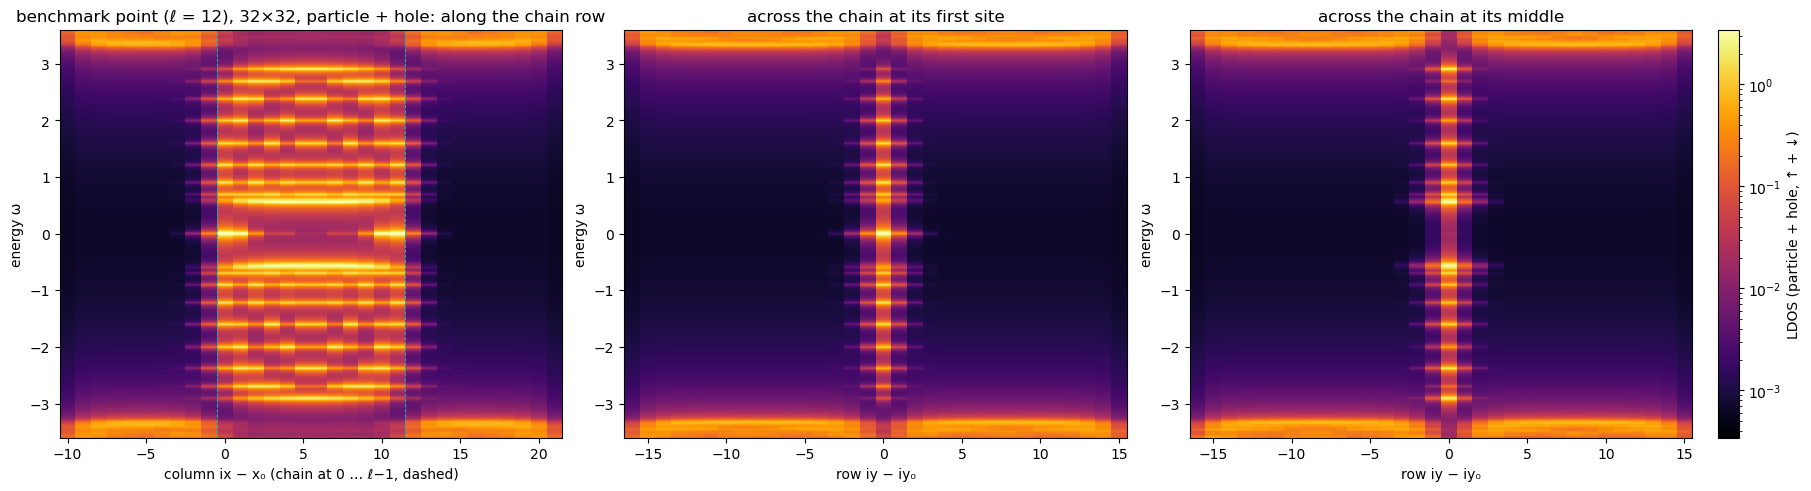

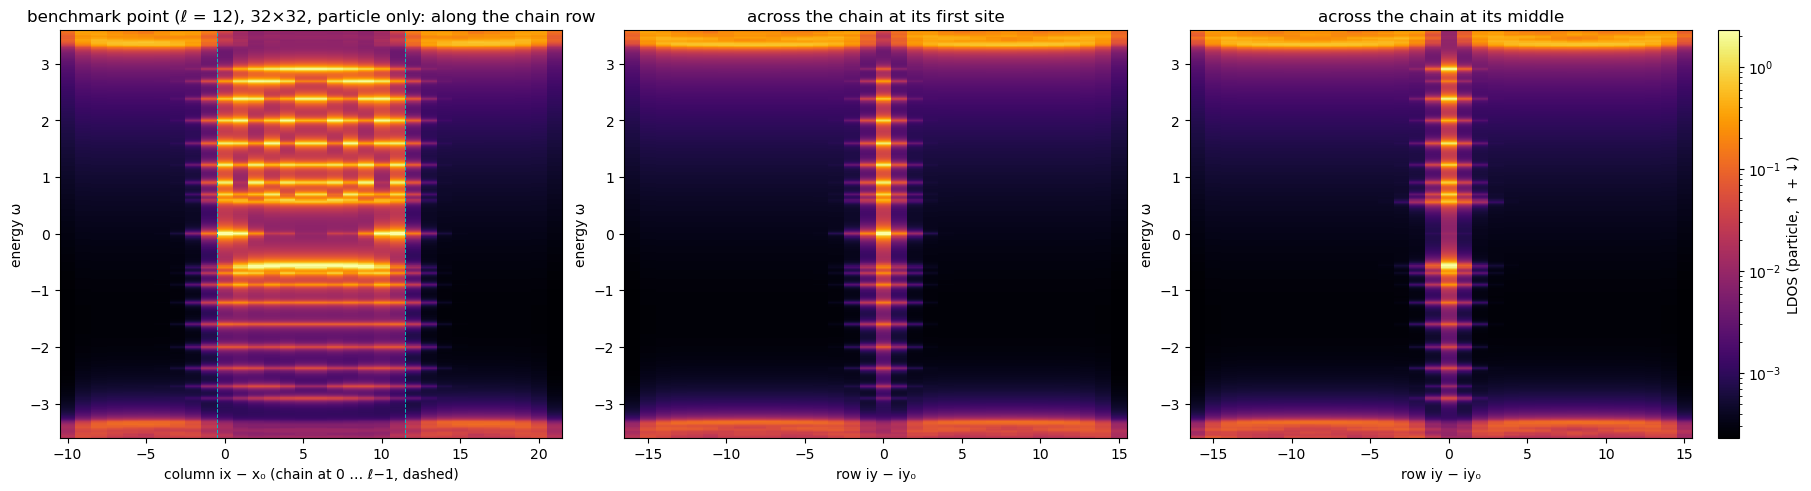

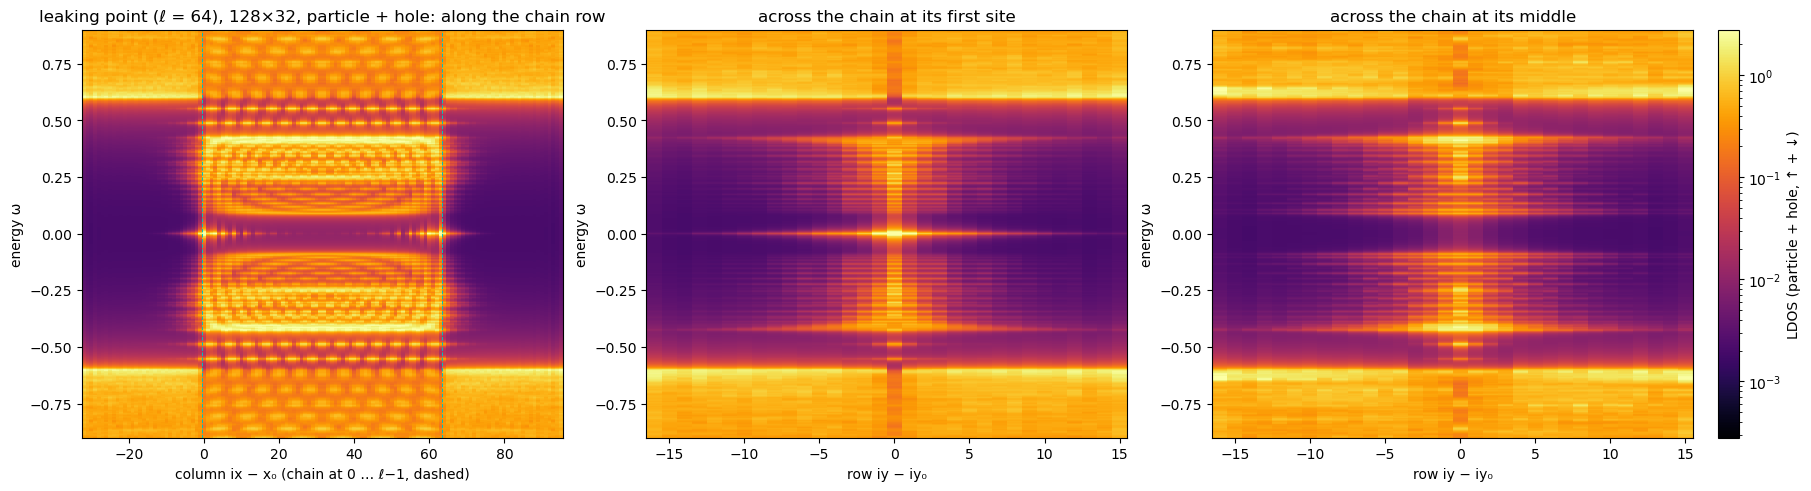

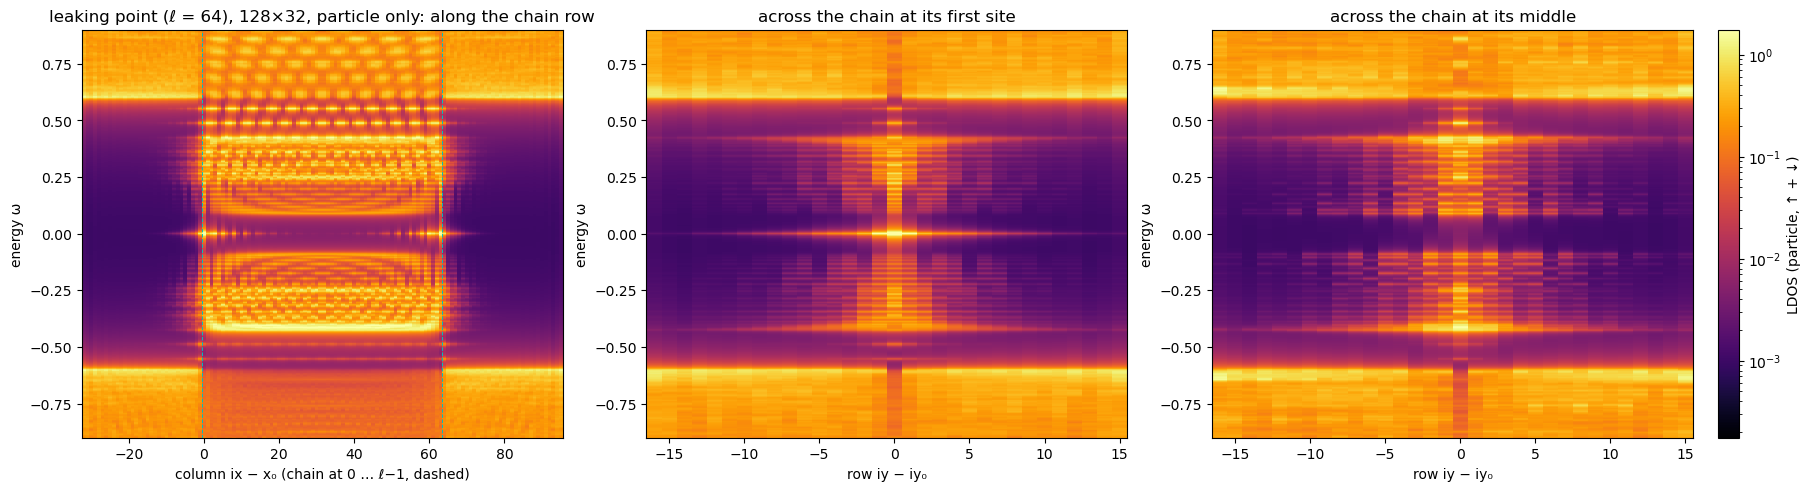

In [ ]:
RUN_DENSE = False
dense_file = "ldos_py_dense.csv"
DENSE_CASES = [("bench", 5, 5, 3.6, 0.02), ("leak", 7, 5, 0.9, 0.004)]

def dense_ldos(pt, Lx, Ly, wmax, eta):
    os.environ["OMP_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = "8"
    p = POINTS[pt]; Nx, Ny = 2**Lx, 2**Ly; N = Nx * Ny; xs, iy0 = chain_sites(Lx, Ly, p["ell"]); x0 = xs[0]
    t_ = time.perf_counter(); E, V = la.eigh(ham(Lx, Ly, p["ell"], **p["P"]).toarray()); t_eig = time.perf_counter() - t_
    V = V.reshape(N, 4, -1); w_all = (np.abs(V)**2).sum(1); w_e = (np.abs(V[:, :2])**2).sum(1)
    omega = np.linspace(-wmax, wmax, 801)
    idx = dict(row=np.arange(Nx) + iy0 * Nx, cross_end=x0 + np.arange(Ny) * Nx, cross_mid=x0 + p["ell"] // 2 + np.arange(Ny) * Nx)
    out = dict(omega=omega, E=E, x0=x0, iy0=iy0, ell=p["ell"], Nx=Nx, Ny=Ny, eta=eta)
    for k, i in idx.items():
        out[k] = lorentz_ldos(E, w_all[i].T, omega, eta); out[k + "_e"] = lorentz_ldos(E, w_e[i].T, omega, eta)
    np.savez(f"{DATA}/heat_{pt}_{Lx}_{Ly}.npz", **out)
    return dict(point=pt, Nx=Nx, Ny=Ny, D=4 * N, t_eigh_s=round(t_eig), rss_GB=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 2**20,
                substrate_gap=p["gap"], n_subgap=int(np.sum(np.abs(E) < p["gap"])))

if RUN_DENSE:
    rows = [in_fresh_process(dense_ldos, *c)[0] for c in DENSE_CASES]
    with open(dense_file, "w") as f:
        f.write(",".join(rows[0]) + "\n")
        for r in rows: f.write(",".join(str(v) for v in r.values()) + "\n")
for r in read_csv(dense_file):
    print(f"{r['point']}: {r['Nx']}×{r['Ny']}, D = {r['D']}, eigh {r['t_eigh_s']} s, {r['rss_GB']:.1f} GB; {r['n_subgap']} states below the substrate gap {r['substrate_gap']}")

def heat_panels(d, key, title, mx=40, ylim_rows=None):
    "Three log-scale heatmaps of a cut file d: chain row, across at the first site, across at the middle."
    w = d["omega"]; x0, iy0, ell = int(d["x0"]), int(d["iy0"]), int(d["ell"])
    xs = d["xcols"] - x0 if "xcols" in d else np.arange(int(d["Nx"])) - x0
    ys = d["yrows"] - iy0 if "yrows" in d else np.arange(int(d["Ny"])) - iy0
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
    R = d["row" + key]; vmax = np.quantile(R, 0.999); vmin = vmax * 1e-4; xr = (xs >= -mx) & (xs <= ell - 1 + mx)
    yr = np.abs(ys) <= (ylim_rows or 10**6)
    im = ax[0].pcolormesh(xs[xr], w, np.maximum(R[:, xr], vmin), norm=LogNorm(vmin, vmax), cmap="inferno", shading="nearest")
    ax[0].axvline(-0.5, color="c", lw=0.7, ls="--"); ax[0].axvline(ell - 0.5, color="c", lw=0.7, ls="--")
    ax[0].set_xlabel("column ix − x₀ (chain at 0 … ℓ−1, dashed)"); ax[0].set_ylabel("energy ω"); ax[0].set_title(f"{title}: along the chain row")
    for j, (k, t) in enumerate((("cross_end", "across the chain at its first site"), ("cross_mid", "across the chain at its middle")), start=1):
        ax[j].pcolormesh(ys[yr], w, np.maximum(d[k + key][:, yr], vmin), norm=LogNorm(vmin, vmax), cmap="inferno", shading="nearest")
        ax[j].set_xlabel("row iy − iy₀"); ax[j].set_ylabel("energy ω"); ax[j].set_title(t)
    fig.colorbar(im, ax=ax[2], label=f"LDOS ({'particle + hole' if key == '' else 'particle'}, ↑ + ↓)")
    plt.show()

for pt, Lx, Ly, _, _ in DENSE_CASES:
    d = np.load(f"{DATA}/heat_{pt}_{Lx}_{Ly}.npz")
    for key in ("", "_e"):
        heat_panels(d, key, f"{POINTS[pt]['title']}, {2**Lx}×{2**Ly}, {'particle + hole' if key == '' else 'particle only'}")

## 4. Subgap LDOS on large substrates (MUMPS shift-invert)

All subgap states by shift-invert `eigsh` with a MUMPS factorization (`mumps_eigsh`, FTZ/DAZ on), with $k$ equal to the subgap count of
section 3 (24 and 106). Asking for more pulls ARPACK into the dense continuum just above the gap edge (dozens of states at
3.313–3.314 and 0.6001–0.6003) and slows it by orders of magnitude; the run records how many of its $k$ states lie inside the gap as a
check. Each case in a fresh process: 256² and 512² four at once, then 1024² one at a time (up to 46 GB).

 point   substrate |    k below gap  max |E| |  factor   eigsh    peak
 bench   256×256   |   24        24   2.9078 |      3s     31s   1.7 GB
  leak   256×256   |  106       106   0.5530 |      3s    132s   2.7 GB
 bench   512×512   |   24        24   2.9078 |     20s    133s   7.1 GB
  leak   512×512   |  106       106   0.5530 |     21s    417s  10.9 GB
 bench  1024×1024  |   24        24   2.9078 |    126s    468s  30.6 GB
  leak  1024×1024  |  106       106   0.5530 |    125s   1779s  46.0 GB


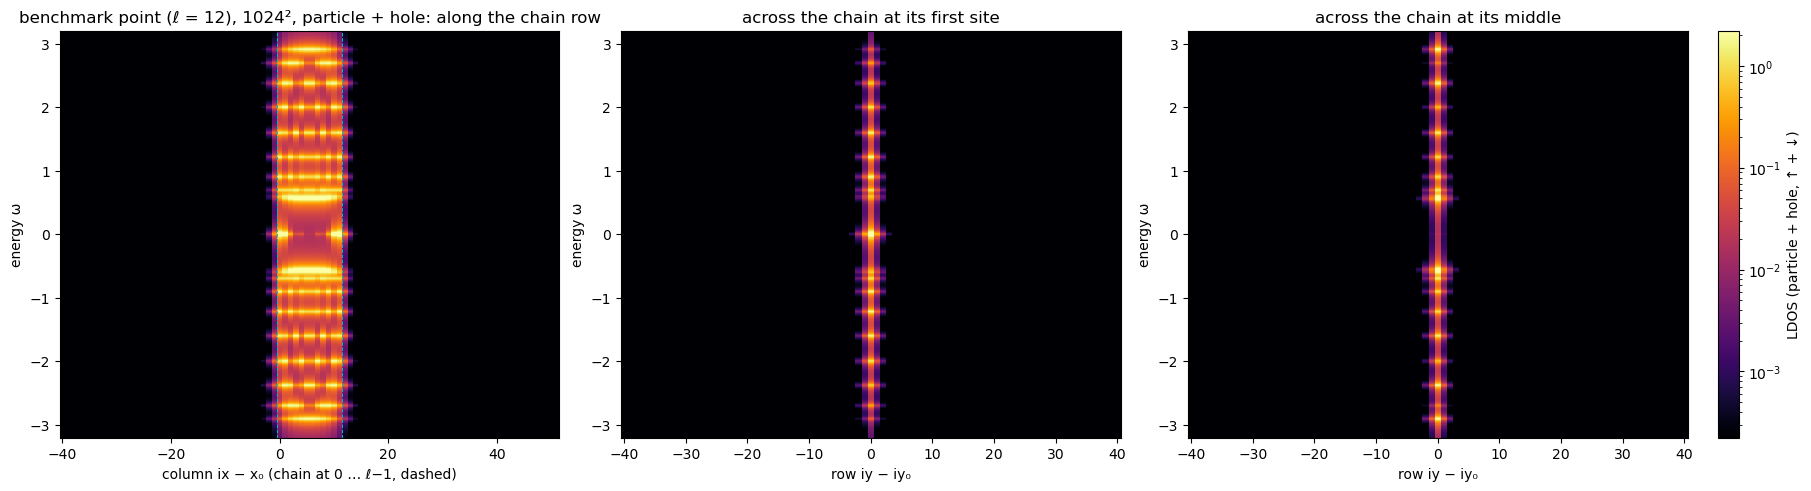

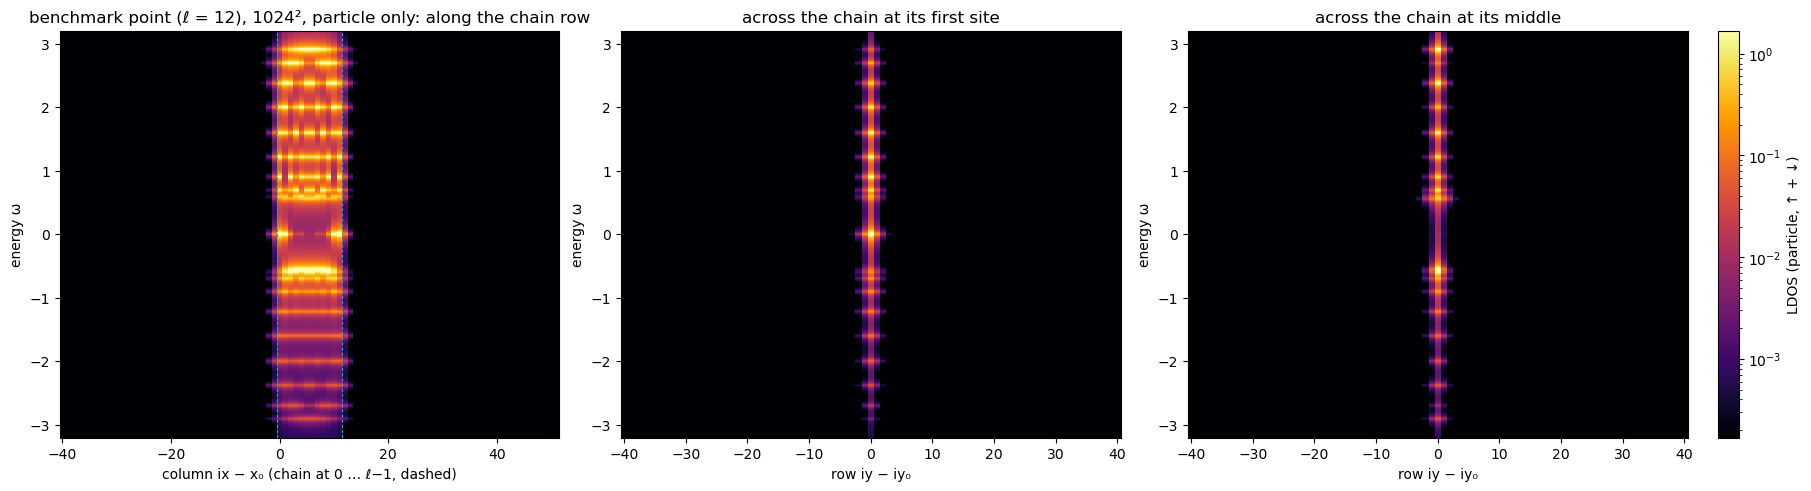

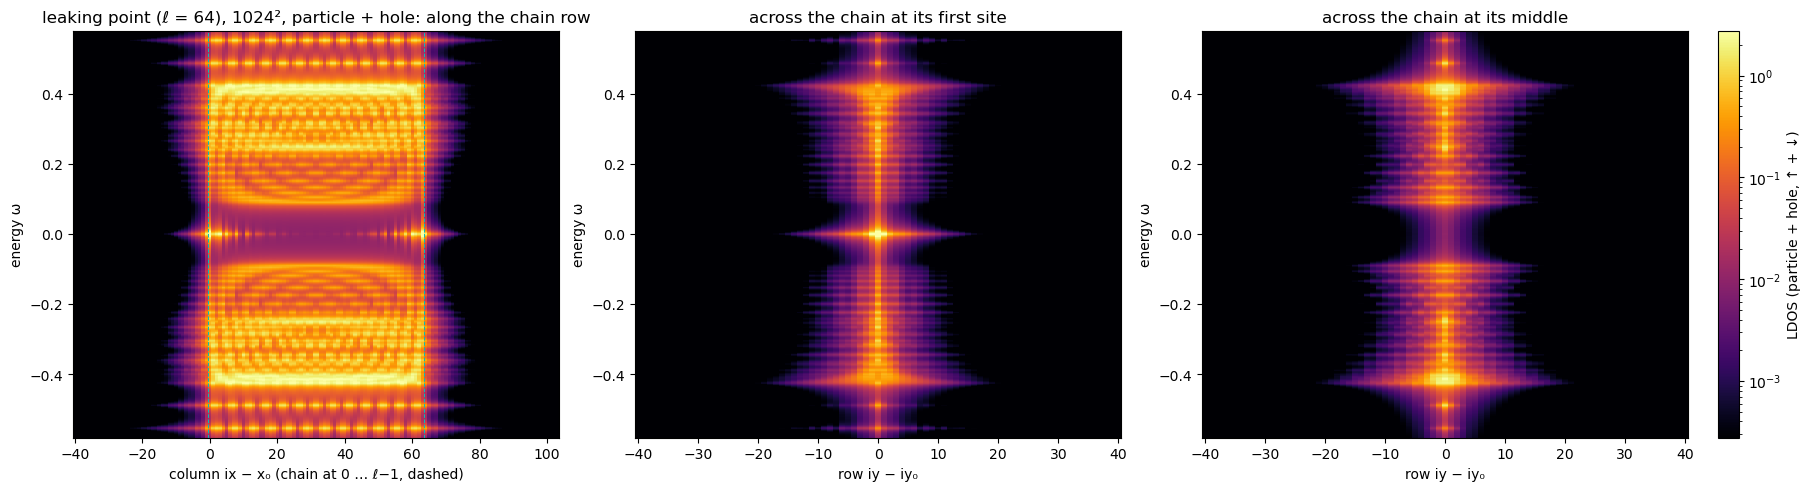

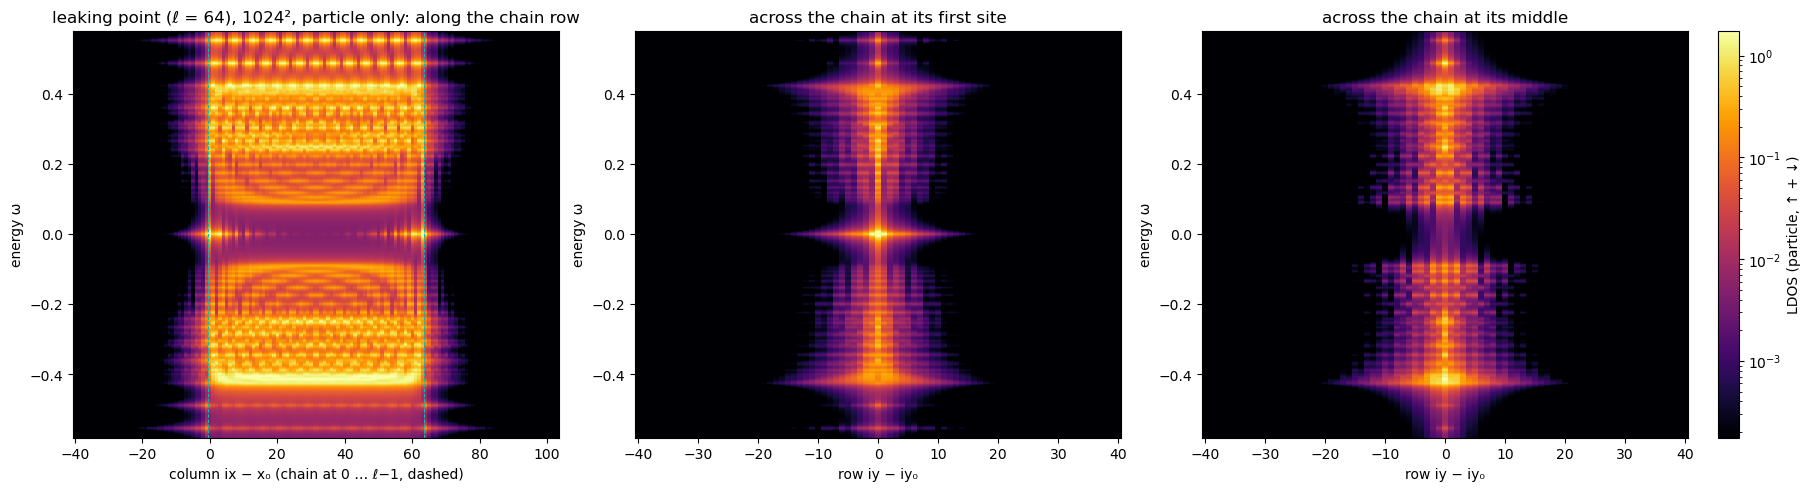

In [ ]:
RUN_SUBGAP = False
subgap_file = "ldos_py_subgap.csv"

def subgap_ldos(pt, L):
    ftz_daz(True)
    p = POINTS[pt]; H = ham(L, L, p["ell"], **p["P"]); idx, cols, rows, x0, iy0 = cut_indices(L, L, p["ell"])
    import mumps
    t_ = time.perf_counter(); ctx = mumps.Context(); ctx.factor(H.tocoo(), ordering="metis"); t_fac = time.perf_counter() - t_
    from scipy.sparse.linalg import eigsh, LinearOperator
    t_ = time.perf_counter()
    E, V = eigsh(H, k=p["nsub"], sigma=0, which="LM", ncv=2 * p["nsub"] + 20, OPinv=LinearOperator(H.shape, matvec=ctx.solve, dtype=complex))
    t_eig = time.perf_counter() - t_
    o = np.argsort(E); E, V = E[o], V[:, o].reshape(-1, 4, p["nsub"])
    omega = np.linspace(-p["wmax"], p["wmax"], 801)
    out = dict(omega=omega, E=E, x0=x0, iy0=iy0, ell=p["ell"], Nx=2**L, Ny=2**L, eta=p["eta"], xcols=cols, yrows=rows)
    for k, i in idx.items():
        out[k] = lorentz_ldos(E, (np.abs(V[i])**2).sum(1).T, omega, p["eta"]); out[k + "_e"] = lorentz_ldos(E, (np.abs(V[i, :2])**2).sum(1).T, omega, p["eta"])
    np.savez(f"{DATA}/heat_sparse_{pt}_{L}.npz", **out)
    return dict(point=pt, Nx=2**L, k=p["nsub"], n_subgap=int(np.sum(np.abs(E) < p["gap"])), max_absE=np.abs(E).max(), t_factor_s=round(t_fac),
                t_eigsh_s=round(t_eig), rss_GB=resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 2**20)

if RUN_SUBGAP:
    from multiprocessing import Pool
    with Pool(4, maxtasksperchild=1) as pool:
        rows = pool.starmap(subgap_ldos, [("bench", 8), ("bench", 9), ("leak", 8), ("leak", 9)])
    rows += [in_fresh_process(subgap_ldos, pt, 10)[0] for pt in ("bench", "leak")]
    with open(subgap_file, "w") as f:
        f.write(",".join(rows[0]) + "\n")
        for r in rows: f.write(",".join(str(v) for v in r.values()) + "\n")
print(f"{'point':>6s} {'substrate':>11s} | {'k':>4s} {'below gap':>9s} {'max |E|':>8s} | {'factor':>7s} {'eigsh':>7s} {'peak':>7s}")
for r in read_csv(subgap_file):
    print(f"{r['point']:>6s} {r['Nx']:5d}×{r['Nx']:<5d} | {r['k']:4d} {r['n_subgap']:9d} {r['max_absE']:8.4f} | {r['t_factor_s']:6d}s {r['t_eigsh_s']:6d}s {r['rss_GB']:5.1f} GB")
for pt in POINTS:
    d = np.load(f"{DATA}/heat_sparse_{pt}_10.npz")
    for key in ("", "_e"):
        heat_panels(d, key, f"{POINTS[pt]['title']}, 1024², {'particle + hole' if key == '' else 'particle only'}", ylim_rows=40)

## 5. Per-site Chebyshev moments (sparse reference for the TN KPM)

The moments $\mu_n = \langle\mathbf r,c|T_n(H/s)|\mathbf r,c\rangle$ of the four components of the first chain site, 512 moments with the doubling
recursion and the scale $s = 1.05\,(|\mu| + |J| + 4\sqrt{t^2+\alpha^2} + |\Delta|)$ of the TN notebook, by sparse products
(`sparse_site_moments`), at 256² and 1024². They are the reference for the TN moments of `msh_substrate_ldos_tn.ipynb`, section 4, and their
cost is the sparse column of `ldos_kpm_site.csv`.

256²      TN  cutoff  1e-10:   304.0 s per site, peak  1617 MB
256²  sparse  cutoff      –:    11.8 s per site, peak   281 MB
256²      TN  cutoff  1e-08:   262.0 s per site, peak  1536 MB
1024²      TN  cutoff  1e-10:   382.0 s per site, peak  1662 MB
1024²  sparse  cutoff      –:   219.3 s per site, peak  3525 MB


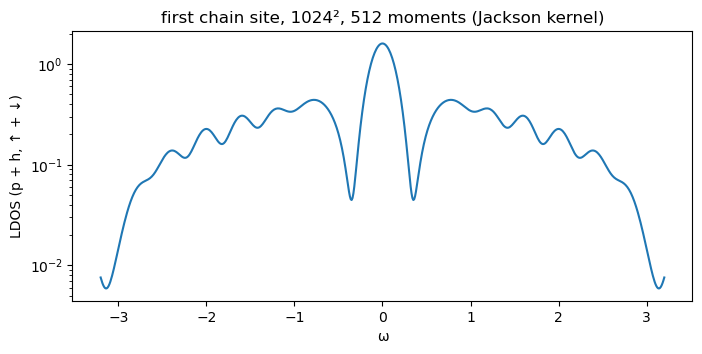

In [ ]:
RUN_KPM = False
KPM_CASES = [("bench", 8), ("bench", 10)]
scale = 1.05 * (7 + 5.8 + 4 * np.sqrt(1 + 0.81) + 2.4)

def kpm_sparse(pt, L, Ncheb=512):
    p = POINTS[pt]; xs, iy0 = chain_sites(L, L, p["ell"]); n = xs[0] + iy0 * 2**L
    t_ = time.perf_counter(); mu = sparse_site_moments(ham(L, L, p["ell"], **p["P"]), n, Ncheb, scale)
    np.save(f"{DATA}/site_kpm_{pt}_{L}_{xs[0]}_{iy0}_n{Ncheb}_m512_sparse.npy", mu)
    return time.perf_counter() - t_

if RUN_KPM:
    for c in KPM_CASES: print(c, f"{in_fresh_process(kpm_sparse, *c)[0]:.1f} s")
for r in read_csv("ldos_kpm_site.csv"):
    cut = "–" if r["method"] == "sparse" else f"{r['cutoff']:.0e}"
    print(f"{r['Nx']}²  {r['method']:>6s}  cutoff {cut:>6s}: {r['secs_per_site']:7.1f} s per site, peak {r['rss_MB']:5d} MB")
w = np.linspace(-3.2, 3.2, 641)
mu = np.load(f"{DATA}/site_kpm_bench_10_506_512_n512_m512_sparse.npy")
plt.figure(figsize=(8, 3.5)); plt.semilogy(w, np.maximum(jackson_ldos(mu, scale, w).sum(1), 1e-6))
plt.xlabel("ω"); plt.ylabel("LDOS (p + h, ↑ + ↓)"); plt.title("first chain site, 1024², 512 moments (Jackson kernel)"); plt.show()

## 6. TN against sparse: figures

Reads the TN results of `msh_substrate_ldos_tn.ipynb` (`data/ldos/zb_tn_*.npz`, `levels_tn_*.npz`). Left: the zero-bias weight of the TN
zero mode at 256²–2048² (the sizes coincide) along the chain row and across the chain; middle: $|w_{\rm TN} - w_{\rm sparse}|$ on the same cuts at
256²–1024²; right: the TN map at 2048². Then the subgap LDOS at 2048² from the TN levels (benchmark point), with the agreement of the TN cuts
with the MUMPS cuts at 256²–1024².

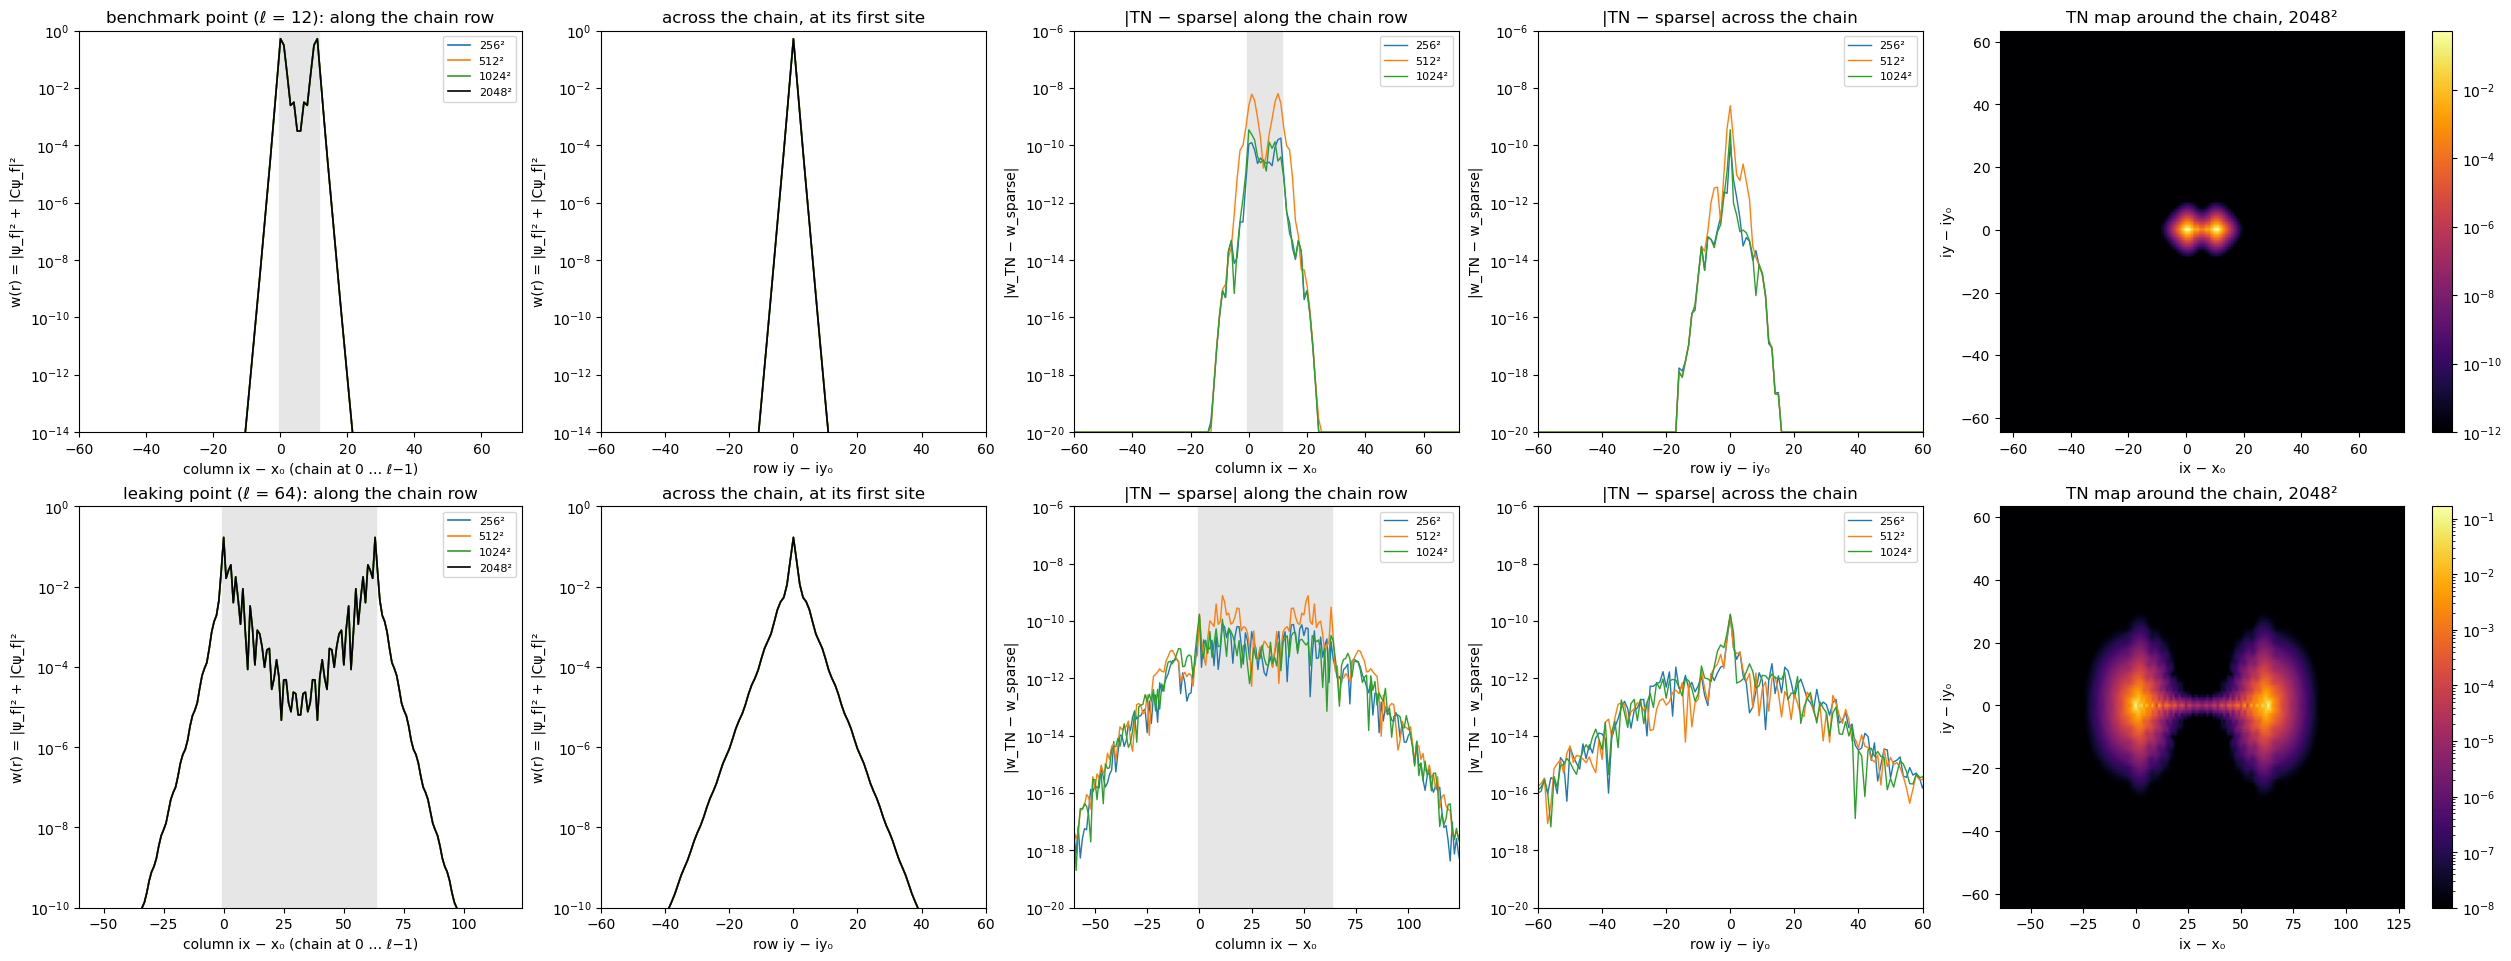

  size |  max|E_TN − E_MUMPS|  max relative cut difference
  256² |              1.6e-09                      7.4e-05
  512² |              6.0e-09                      1.9e-05
 1024² |              1.3e-09                      3.0e-06


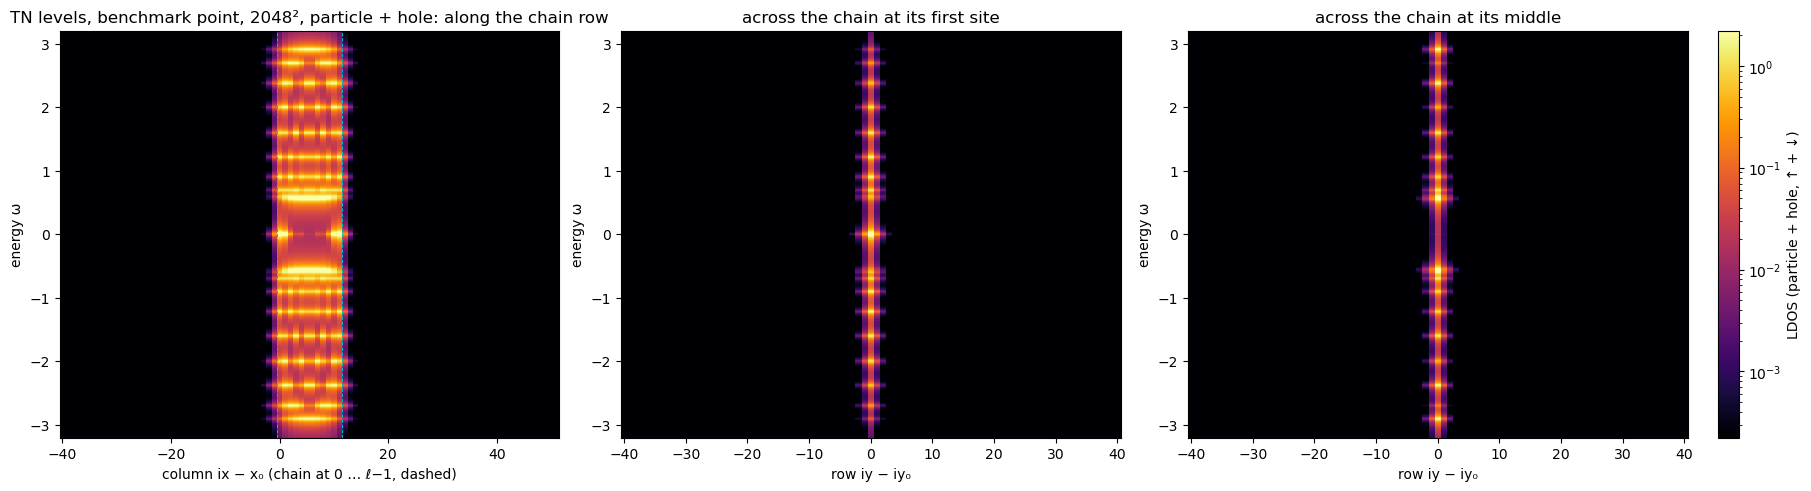

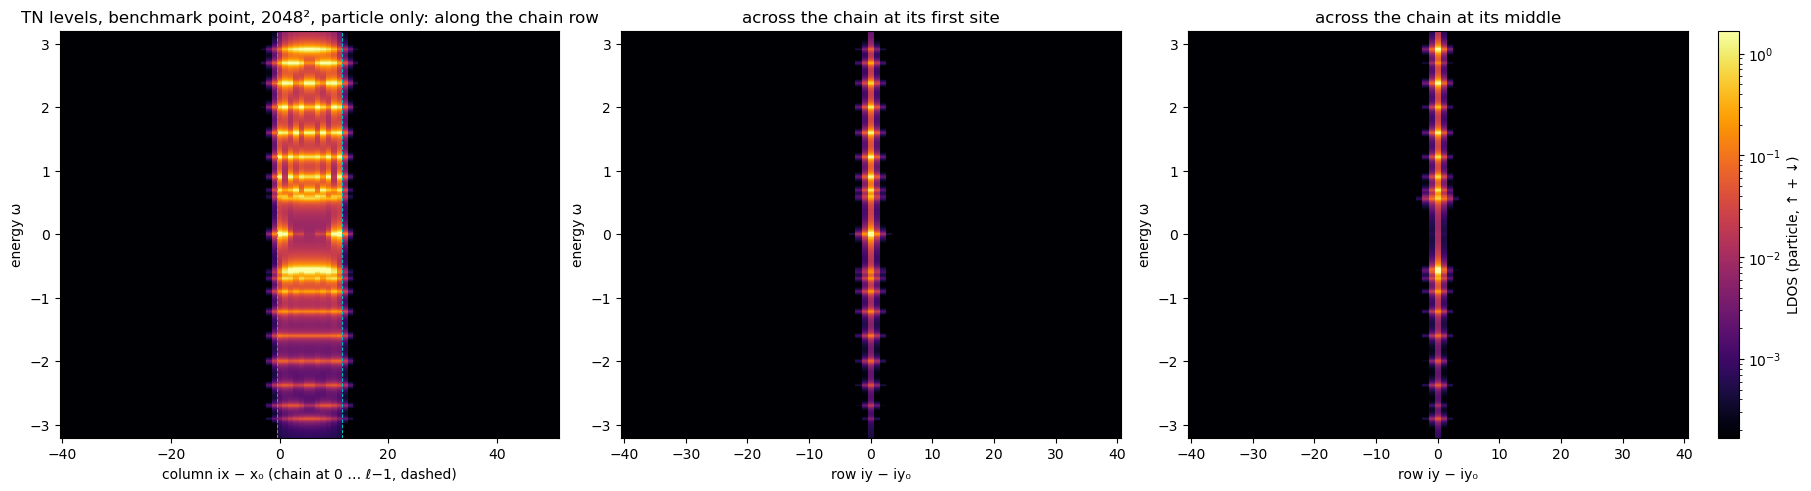

In [ ]:
floor = {"bench": 1e-14, "leak": 1e-10}; colors = {8: "tab:blue", 9: "tab:orange", 10: "tab:green", 11: "k"}
fig, ax = plt.subplots(2, 5, figsize=(25, 9.5), constrained_layout=True, gridspec_kw=dict(width_ratios=[1.15, 1, 1, 1, 1.05]))
for i, pt in enumerate(POINTS):
    ell = POINTS[pt]["ell"]
    for L in (8, 9, 10, 11):
        t = np.load(f"{DATA}/zb_tn_{pt}_{L}_{L}.npz"); x0, iy0 = int(np.ravel(t["x0"])[0]), int(np.ravel(t["iy0"])[0])
        ax[i, 0].semilogy(np.arange(len(t["row"])) - x0, np.maximum(t["row"], 1e-30), color=colors[L], lw=1.2, label=f"{2**L}²")
        ax[i, 1].semilogy(np.arange(len(t["cross_end"])) - iy0, np.maximum(t["cross_end"], 1e-30), color=colors[L], lw=1.2)
        if L < 11:
            s = np.load(f"{DATA}/zb_{pt}_{L}_{L}.npz")
            ax[i, 2].semilogy(np.arange(len(s["row"])) - x0, np.maximum(np.abs(t["row"] - s["row"]), 1e-20), color=colors[L], lw=1, label=f"{2**L}²")
            ax[i, 3].semilogy(np.arange(len(s["cross_end"])) - iy0, np.maximum(np.abs(t["cross_end"] - s["cross_end"]), 1e-20), color=colors[L], lw=1, label=f"{2**L}²")
    ax[i, 0].axvspan(-0.5, ell - 0.5, color="0.9", zorder=0); ax[i, 2].axvspan(-0.5, ell - 0.5, color="0.9", zorder=0)
    for j, (xl, tt, lim, yl) in enumerate((("column ix − x₀ (chain at 0 … ℓ−1)", f"{POINTS[pt]['title']}: along the chain row", (-60, ell + 60), (floor[pt], 1)),
                                           ("row iy − iy₀", "across the chain, at its first site", (-60, 60), (floor[pt], 1)),
                                           ("column ix − x₀", "|TN − sparse| along the chain row", (-60, ell + 60), (1e-20, 1e-6)),
                                           ("row iy − iy₀", "|TN − sparse| across the chain", (-60, 60), (1e-20, 1e-6)))):
        ax[i, j].set_xlim(*lim); ax[i, j].set_ylim(*yl); ax[i, j].set_xlabel(xl); ax[i, j].set_title(tt)
        ax[i, j].set_ylabel("w(r) = |ψ_f|² + |Cψ_f|²" if j < 2 else "|w_TN − w_sparse|")
        if j != 1: ax[i, j].legend(fontsize=8)
    win = np.load(f"{DATA}/zb_tn_{pt}_11_11.npz")["win"]
    im = ax[i, 4].imshow(np.maximum(win, 1e-16), origin="lower", cmap="inferno", norm=LogNorm(vmin=floor[pt] * 100, vmax=win.max()),
                         extent=[-64.5, ell + 63.5, -64.5, 63.5], aspect="auto")
    ax[i, 4].set_xlabel("ix − x₀"); ax[i, 4].set_ylabel("iy − iy₀"); ax[i, 4].set_title("TN map around the chain, 2048²"); fig.colorbar(im, ax=ax[i, 4])
plt.show()

def tn_cuts(L):
    "LDOS cuts of the TN levels (φ₊ and Cφ₊) with the Lorentzian and window of section 4, benchmark point."
    t = np.load(f"{DATA}/levels_tn_bench_{L}.npz"); E = t["E"]; p = POINTS["bench"]; omega = np.linspace(-p["wmax"], p["wmax"], 801)
    out = dict(omega=omega, E=E, xcols=t["xcols"], yrows=t["yrows"], x0=int(t["x0"][0]), iy0=int(t["iy0"][0]), ell=int(t["ell"][0]))
    for k in ("row", "cross_end", "cross_mid"):
        pa, ho = t[k][0], t[k][1]                                  # particle and hole weight of φ₊ (|Cφ|² = |φ|²; particle of Cφ = hole of φ)
        out[k] = lorentz_ldos(E, (pa + ho).T, omega, p["eta"]) + lorentz_ldos(-E, (pa + ho).T, omega, p["eta"])
        out[k + "_e"] = lorentz_ldos(E, pa.T, omega, p["eta"]) + lorentz_ldos(-E, ho.T, omega, p["eta"])
    return out

print(f"{'size':>6s} | {'max|E_TN − E_MUMPS|':>20s} {'max relative cut difference':>28s}")
for L in (8, 9, 10):
    a, s = tn_cuts(L), np.load(f"{DATA}/heat_sparse_bench_{L}.npz"); Es = np.sort(s["E"][s["E"] > 0])
    rel = max(np.abs(a[k] - s[k]).max() / s[k].max() for k in ("row", "cross_end", "cross_mid", "row_e", "cross_end_e", "cross_mid_e"))
    print(f"{2**L:5d}² | {np.abs(np.sort(a['E']) - Es).max():20.1e} {rel:28.1e}")
d = tn_cuts(11)
for key in ("", "_e"):
    heat_panels(d, key, f"TN levels, benchmark point, 2048², {'particle + hole' if key == '' else 'particle only'}", ylim_rows=40)

## 7. Summary

- **Subgap states are few and size-independent.** Below the substrate gap only the states bound to the chain remain: 24 at the benchmark
  point (gap 3.3) and 106 at the leaking point (gap 0.60), with the same spectrum from 32×32 to 1024². The subgap LDOS is therefore exact
  from those states alone and converged in the substrate size.
- **Zero-bias LDOS.** At the benchmark point 89 % of the in-gap weight is on the chain row, at the chain ends, falling by about 1.3 decades
  per site into the substrate; at the leaking point only 32 %, with lobes about 30 rows high around each chain end, falling about a decade
  every 4 rows ($e^{-|\Delta y|/2}$). Reading it off a saved zero mode costs 0.1 s.
- **Energy-resolved LDOS.** Benchmark: discrete Shiba levels from 0.55 to 2.9 confined to the chain row and its neighbours, the continuum
  starting sharply at ±3.3. Leaking: a Shiba band 0.09–0.42 with standing waves along the chain, extending over ±5 rows at mid-band and ±20
  rows near its edges, discrete levels up to the gap edge at 0.60.
- **Cost of the sparse route.** All subgap states by MUMPS shift-invert take 34, 153, 594 s at the benchmark point and 135, 438, 1904 s
  at the leaking point at 256², 512², 1024², with 1.7–46 GB; at 2048² the factorization alone needs about 121 GB. A per-site KPM
  spectrum costs 12 s at 256² and 219 s at 1024² (∝ N). Dense diagonalization stops at 128×32 (730 s, 8.3 GB).
- **Against the TN** (section 6, and `msh_substrate_ldos_tn.ipynb`): the TN zero modes agree to $6\times10^{-9}$ and $8\times10^{-10}$, the TN
  levels to $10^{-9}$ in energy and $2\times10^{-5}$ in the cuts; the TN reaches 2048² with 2.6 GB.